# Stage-by-stage thresholding-rule sensitivity 
This notebook runs the experiment behind Fig. 12 and Supplementary Figs. S1 and S2 of the article one stage at a time, and shows the intermediate results of each stage.

| Stage | Function in `thresholding_rule_sensitivity.py` | Result |
|---|---|---|
| 1 | `simulate_frames()` | 120 OFDM frames at each Eb/N0 value, received under AWGN and under Middleton Class-A noise |
| 2 | `evaluate_ber()` | BER of the 60 wavelet configurations and of the receiver without denoising |
| 3 | `fig12_table()`, `plot_fig12_panel()` | Fig. 12 (db4, J = 3): (a) AWGN, (b) impulsive noise |
| 4 | `plot_sensitivity_grid()` | Supplementary Fig. S1 (AWGN) and Fig. S2 (impulsive noise) |

The figures and the BER tables are saved in `results/`, exactly as by the script.

**How to run.**

1. Open this folder in Visual Studio Code.
2. Open this notebook and choose the project's Python environment with **Select Kernel** (top right).
3. Click **Run All**. The whole notebook takes about 1 minute; stage 2 takes most of it.

The notebook calls the same functions as the script, with the same settings and seed, so it produces the same numbers.

## Setup

In [1]:
import platform
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "thresholding_core.py").exists():
    raise FileNotFoundError("Start the notebook from the folder that contains thresholding_core.py.")
sys.path.insert(0, str(ROOT))

import thresholding_core as core
import thresholding_rule_sensitivity as sens

print("Python     ", platform.python_version())
for pkg in ["numpy", "pandas", "pywavelets", "matplotlib"]:
    print(f"{pkg:<11}", version(pkg))

OUT = ROOT / "results"
OUT.mkdir(exist_ok=True)

Python      3.11.9
numpy       2.4.6
pandas      3.0.6
pywavelets  1.9.0
matplotlib  3.11.2


---
## 1. Transmitted and received frames

Each frame carries 14 OFDM symbols:

- 64-point FFT with a 16-sample cyclic prefix, giving 1120 complex samples per frame;
- 48 active subcarriers carrying QPSK, giving 1344 bits per frame;
- the waveform is normalised to unit average power.

The same transmitted frame is received twice: once with complex AWGN and once with complex Middleton Class-A noise (A = 0.005, T = 0.05). The total noise power follows from Eb/N0, which runs from 0 to 16 dB in steps of 2 dB. There are 120 frames per Eb/N0 value, and one random stream with seed 21 generates everything.

In [2]:
frames = sens.simulate_frames()
f0 = frames[0]
print(f"{len(frames)} Eb/N0 values x {f0.bits.shape[0]} frames, {f0.rx['AWGN'].shape[1]} complex samples "
      f"and {f0.bits.shape[1]} bits per frame, {f0.bits.size} bits per Eb/N0 value")

# Impulsive noise: most of its power sits in a few samples. Share of the noise power carried by the 1 % largest samples:
tx = np.array([core.ofdm_modulate(b) for b in f0.bits])
tx /= np.sqrt(np.mean(np.abs(tx) ** 2, axis=1, keepdims=True))
for noise in sens.NOISES:
    p = np.sort((np.abs(f0.rx[noise] - tx) ** 2).ravel())[::-1]
    print(f"{noise:<10} share of noise power in the 1 % largest samples: {p[: p.size // 100].sum() / p.sum():.1%}")

9 Eb/N0 values x 120 frames, 1120 complex samples and 1344 bits per frame, 161280 bits per Eb/N0 value
AWGN       share of noise power in the 1 % largest samples: 5.6%
Middleton  share of noise power in the 1 % largest samples: 95.4%


## 2. BER of every configuration

The receiver suppresses impulses in the in-phase and the quadrature component separately:

1. DWT to level J (periodization).
2. In every detail level, the coefficients with |c| ≥ 4σ form the impulse estimate, where σ = median(|c|)/0.6745 of that level. They are shaped by the hard, soft or garrote rule.
3. The impulse estimate is reconstructed and subtracted from the received component.

The receiver then demodulates the OFDM symbols and takes hard QPSK decisions.

All 5 wavelets × 4 levels × 3 rules = 60 configurations are evaluated under both noise models, together with the receiver without denoising.

In [3]:
ber = sens.evaluate_ber(frames)
print(len(ber), "BER values")
ber.head(8)

  Eb/N0 = 0 dB done
  Eb/N0 = 2 dB done
  Eb/N0 = 4 dB done
  Eb/N0 = 6 dB done
  Eb/N0 = 8 dB done
  Eb/N0 = 10 dB done
  Eb/N0 = 12 dB done
  Eb/N0 = 14 dB done
  Eb/N0 = 16 dB done
1440 BER values


,noise,wavelet,level,EbN0_dB,threshold_rule,bit_errors,total_bits,BER
0,AWGN,haar,2,0.0,No denoising,16484,161280,0.102207
1,AWGN,haar,2,0.0,Hard,16510,161280,0.102369
2,AWGN,haar,2,0.0,Soft,16486,161280,0.102220
3,AWGN,haar,2,0.0,Garrote,16487,161280,0.102226
4,Middleton,haar,2,0.0,No denoising,10781,161280,0.066846
5,Middleton,haar,2,0.0,Hard,4079,161280,0.025291
6,Middleton,haar,2,0.0,Soft,6334,161280,0.039273
7,Middleton,haar,2,0.0,Garrote,4743,161280,0.029408


## 3. Thresholding performance

Fig. 12 shows the BER of the db4, J = 3 configuration:

- (a) under AWGN;
- (b) under Middleton Class-A impulsive noise.

A BER of zero (no bit errors in 161,280 bits) cannot be drawn on a logarithmic axis. Matplotlib draws such a point as a vertical drop to the bottom of the panel.

In [4]:
table = sens.fig12_table(ber)
table.to_csv(OUT / "fig12_ber_db4_J3.csv", index=False)
table.set_index("EbN0_dB").apply(lambda col: col.map("{:.3e}".format))

,AWGN - No denoising,AWGN - Hard,AWGN - Soft,AWGN - Garrote,Middleton - No denoising,Middleton - Hard,Middleton - Soft,Middleton - Garrote
EbN0_dB,,,,,,,,
0.0,1.022e-01,1.024e-01,1.022e-01,1.022e-01,6.685e-02,2.684e-02,4.351e-02,3.420e-02
2.0,5.497e-02,5.525e-02,5.498e-02,5.498e-02,5.576e-02,2.369e-02,3.594e-02,2.882e-02
4.0,2.233e-02,2.263e-02,2.233e-02,2.232e-02,3.610e-02,1.653e-02,2.326e-02,1.964e-02
6.0,5.754e-03,5.946e-03,5.766e-03,5.773e-03,2.323e-02,1.120e-02,1.432e-02,1.192e-02
8.0,7.875e-04,8.867e-04,7.875e-04,7.875e-04,1.215e-02,5.965e-03,7.217e-03,6.411e-03
10.0,1.240e-05,1.426e-04,1.240e-05,1.240e-05,4.867e-03,2.499e-03,2.933e-03,2.573e-03
12.0,0.000e+00,1.054e-04,0.000e+00,0.000e+00,1.296e-03,8.743e-04,9.301e-04,8.495e-04
14.0,0.000e+00,2.480e-05,0.000e+00,0.000e+00,3.472e-04,2.232e-04,1.736e-04,1.550e-04
16.0,0.000e+00,6.200e-06,0.000e+00,0.000e+00,3.100e-05,4.340e-05,3.100e-05,3.100e-05


saved: fig12a_thresholding_awgn.pdf
saved: fig12a_thresholding_awgn.png
saved: fig12b_thresholding_impulsive.pdf
saved: fig12b_thresholding_impulsive.png


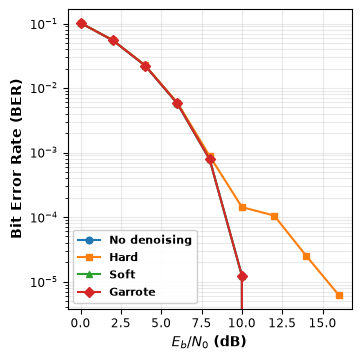

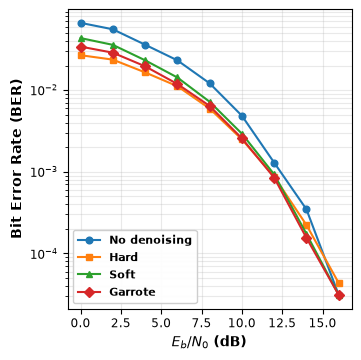

In [5]:
for noise in sens.NOISES:
    fig = sens.plot_fig12_panel(table, noise)
    for path in sens.save_figure(fig, sens.FIG12_FILES[noise], OUT):
        print("saved:", path.name)

## 4. Thresholding sensitivity over wavelet families and decomposition levels 

Rows are the mother wavelets (haar, db4, sym4, coif4, bior4.4) and columns are the decomposition levels (J = 2 to 5). Every panel shows no denoising and the three rules. The db4, J = 3 panel repeats Fig. 12.(Figures S1 and S2)

saved: figS1_thresholding_sensitivity_awgn.pdf
saved: figS1_thresholding_sensitivity_awgn.png


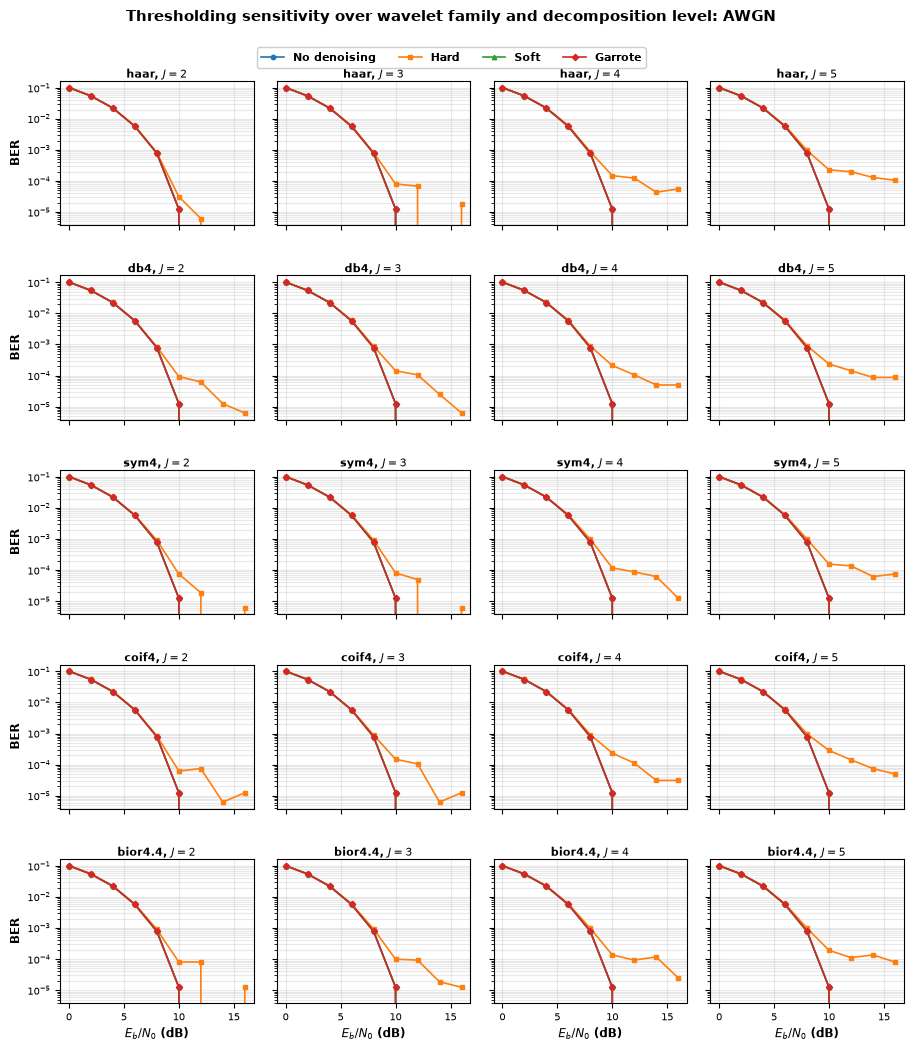

In [6]:
fig = sens.plot_sensitivity_grid(ber, "AWGN")
for path in sens.save_figure(fig, sens.GRID_FILES["AWGN"], OUT):
    print("saved:", path.name)

saved: figS2_thresholding_sensitivity_impulsive.pdf
saved: figS2_thresholding_sensitivity_impulsive.png


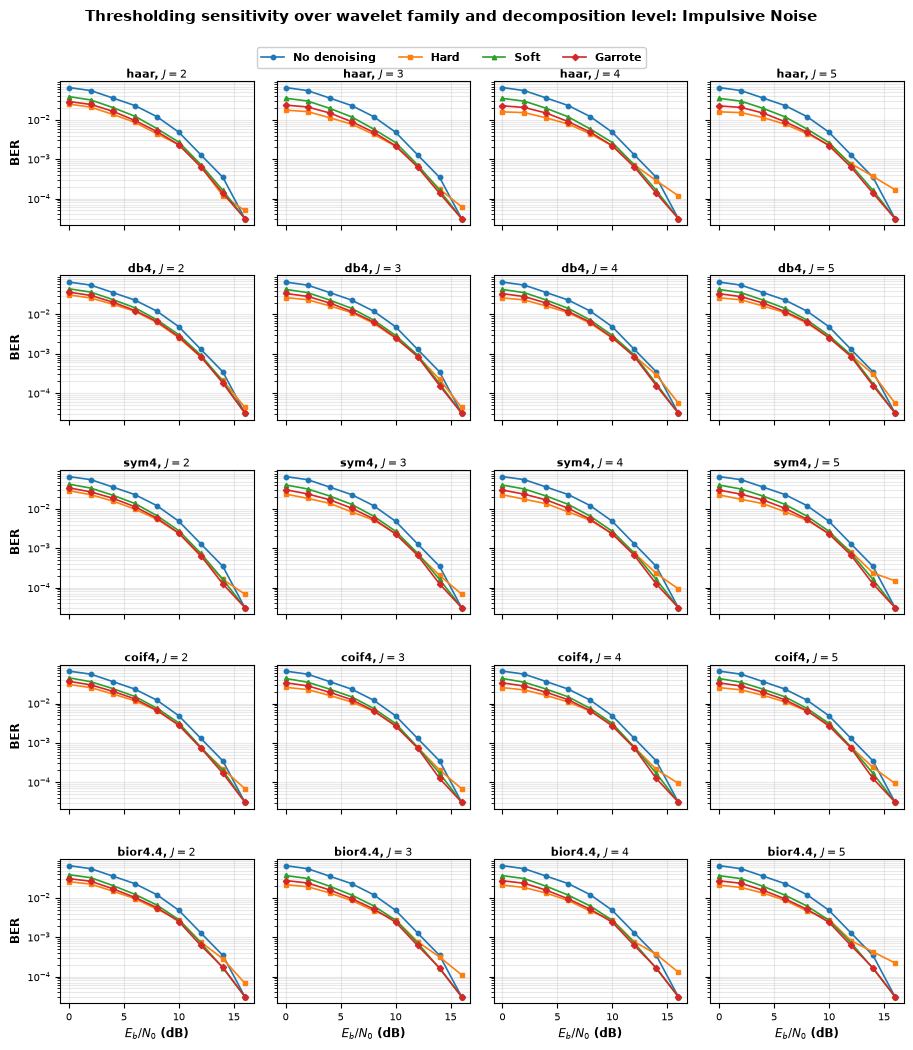

In [7]:
fig = sens.plot_sensitivity_grid(ber, "Middleton")
for path in sens.save_figure(fig, sens.GRID_FILES["Middleton"], OUT):
    print("saved:", path.name)

In [8]:
ber[ber["EbN0_dB"] == 16].pivot_table(index=["noise", "wavelet", "level"], columns="threshold_rule",
                                     values="bit_errors", aggfunc="first")[list(sens.CURVES)]

threshold_rule           No denoising  Hard  Soft  Garrote
noise     wavelet level                                   
AWGN      bior4.4 2                 0     2     0        0
                  3                 0     2     0        0
                  4                 0     4     0        0
                  5                 0    13     0        0
          coif4   2                 0     2     0        0
                  3                 0     2     0        0
                  4                 0     5     0        0
                  5                 0     8     0        0
          db4     2                 0     1     0        0
                  3                 0     1     0        0
                  4                 0     8     0        0
                  5                 0    14     0        0
          haar    2                 0     0     0        0
                  3                 0     3     0        0
                  4                 0     9     0        0
                  5                 0    17     0        0
          sym4    2                 0     1     0        0
                  3                 0     1     0        0
                  4                 0     2     0        0
                  5                 0    12     0        0
Middleton bior4.4 2                 5    11     5        5
                  3                 5    18     5        5
                  4                 5    21     5        5
                  5                 5    36     5        5
          coif4   2                 5    11     5        5
                  3                 5    11     5        5
                  4                 5    15     5        5
                  5                 5    15     5        5
          db4     2                 5     7     5        5
                  3                 5     7     5        5
                  4                 5     9     5        5
                  5                 5     9     5        5
          haar    2                 5     8     5        5
                  3                 5    10     5        5
                  4                 5    19     5        5
                  5                 5    27     5        5
          sym4    2                 5    11     5        5
                  3                 5    11     5        5
                  4                 5    15     5        5
                  5                 5    24     5        5

## Save the BER of every configuration

In [9]:
ber.to_csv(OUT / "thresholding_ber_all_configurations.csv", index=False)
print("Files in results/:", *sorted(p.name for p in OUT.iterdir()), sep="\n  ")

Files in results/:
  fig12_ber_db4_J3.csv
  fig12a_thresholding_awgn.pdf
  fig12a_thresholding_awgn.png
  fig12b_thresholding_impulsive.pdf
  fig12b_thresholding_impulsive.png
  figS1_thresholding_sensitivity_awgn.pdf
  figS1_thresholding_sensitivity_awgn.png
  figS2_thresholding_sensitivity_impulsive.pdf
  figS2_thresholding_sensitivity_impulsive.png
  thresholding_ber_all_configurations.csv
